## Сравниваем swow и случайный граф.

для начала берем 5000 слов.

In [21]:
from pathlib import Path

import numpy as np
import experiment as exp

DATA_FILE = Path("SWOW-EN18/strength.SWOW-EN.R1.20180827.csv")
N_WORDS = 5000
SEED = 42

In [22]:
data = exp.load_associations(DATA_FILE)
print(f"Строк в таблице: {len(data):,}")
data.head()

Строк в таблице: 483,589


,cue,response,weight
0,a,one,0.216495
1,a,the,0.164948
2,a,b,0.092784
3,a,an,0.041237
4,a,first,0.030928




Берём слова с наибольшим суммарным весом входящих ассоциаций среди слов, которые также были стимулами. Затем оставляем связи только между выбранными словами. Получим индуцированный плотный подграф.

In [ ]:
words = exp.select_words(data, N_WORDS)
A = exp.build_matrix(data, words)

print("Размер матрицы:", A.shape)
print("Число дуг:", np.count_nonzero(A))
print("Слов без исходящих дуг:", np.count_nonzero(A.sum(axis=1) == 0))
print("Первые 15 слов:", words[:15])
print("Фрагмент матрицы A:")
print(A[:5, :5])

Размер матрицы: (5000, 5000)
Число дуг: 140424
Слов без исходящих дуг: 0
Первые 15 слов: ['money', 'food', 'water', 'car', 'music', 'old', 'sex', 'love', 'dog', 'bird', 'happy', 'red', 'green', 'sad', 'cold']
Фрагмент матрицы A:
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]


Случайный граф

Создадим `A_random`: число вершин, число дуг и набор ненулевых весов будут точно такими же, но сами дуги распределим случайно. степени пока не контролируем.

In [24]:
A_random = exp.random_matrix(A, seed=SEED)

print("Дуг в SWOW:", np.count_nonzero(A))
print("Дуг в случайном графе:", np.count_nonzero(A_random))
print("Сумма весов в SWOW:", round(A.sum(), 3))
print("Сумма весов в случайном графе:", round(A_random.sum(), 3))

Дуг в SWOW: 140424
Дуг в случайном графе: 140424
Сумма весов в SWOW: 4076.107
Сумма весов в случайном графе: 4076.107


In [25]:
values, vectors = exp.spectrum(A)
random_values, random_vectors = exp.spectrum(A_random)

print("Первые 10 собственных значений SWOW:")
print(np.round(values[:10], 3))

Первые 10 собственных значений SWOW:
[0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j 0.865+0.j
 0.753+0.j 0.743+0.j 0.711+0.j]


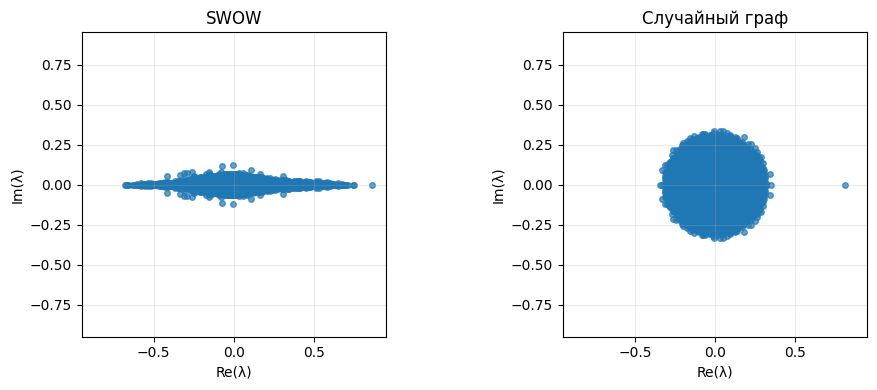

In [26]:
fig = exp.plot_spectra(values, random_values)
fig.savefig("figs/spectra.png", dpi=180)

 $\mathrm{IPR}(v)=\sum_i |v_i|^4$. Равномерно распределённый по модулю вектор имеет IPR = $1/n,$ а вектор с одной ненулевой координатой — IPR = 1.

На графике каждая точка — один собственный вектор. Больший IPR означает концентрацию на меньшем числе слов.

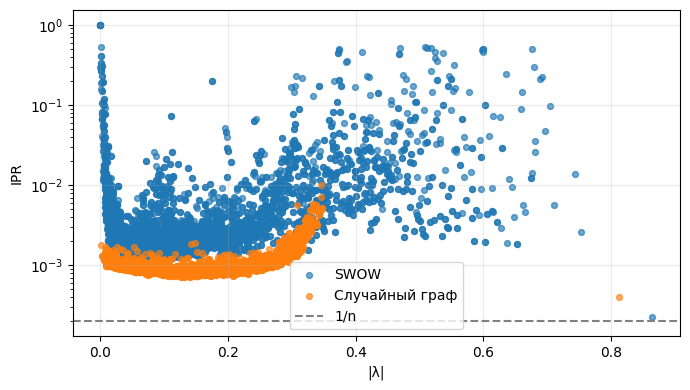

In [27]:
fig = exp.plot_ipr(values, vectors, random_values, random_vectors)
fig.savefig("figs/ipr.png", dpi=180)

Возьмём три вектора с самым большим IPR среди тех, у которых $|\lambda| > 0.2\max|\lambda|$; эта отсечка нужна, чтобы пока не изучать почти нулевые собственные значения. Выведем восемь слов с самыми большими по модулю координатами в каждом векторе.

In [28]:
exp.localized_words(values, vectors, words, n_vectors=3, n_words=8)

,lambda,IPR,words
0,-0.509+0.000j,0.5233,"harley, davidson, motorcycle, helmet, native a..."
1,0.512+0.000j,0.5123,"harley, davidson, motorcycle, occasionally, no..."
2,-0.518+0.000j,0.5112,"flora, fauna, plants, prior, before, after, pr..."


правда немножко смахивает на семантические кластеры

In [29]:
Path("words.txt").write_text("\n".join(words), encoding="utf-8")

35349